# OBPS Data Processing

Processing OBPS data files into MESSAGE-ix format

In [1]:
# Read Excel files and import relevant packages

import pandas as pd
import os
import numpy as np
import re

# Sys and OS Operations
os.chdir("../../")




In [3]:
input_file = "data/MESSAGE_OBPS_stringent(2.0).csv"
read_file = pd.read_csv(input_file, sep=',')

mapping = pd.read_excel("data/obps_inputs_clean.xlsx", sheet_name="Mapping")


# Create dataframe that is a copy of the original dataframe, but with the corrsponding technologies in a "technology column"

mapping_dict = mapping.groupby('variable')['technology'].apply(list).to_dict()
new_units_dict = dict(zip(read_file["unit [tCO2/-]"].unique(), ["tonne", "tonne", "MWh", "GWh", "tonne", "GWh", 
                                                                "CAN-CWB", "m3", "barrel_bitumen", "tonne_h2", 
                                                                "MWh", "m3", "AB_index", "100e3_m3", "1e3_AB-CWB", 
                                                                "CAN-CWB", "barrel_heavy_crude", "-"]))

#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#


# Data Viewer Cell

In [3]:
#mapping
read_file

,variable,region,time,value,unit [tCO2/-]
0,Input|Policy|OBPS|Standard|Aluminum|Alumina,Canada,2019,1.58,Tonnes of liquid aluminium
1,Input|Policy|OBPS|Standard|Aluminum|Alumina,Canada,2020,1.58,Tonnes of liquid aluminium
2,Input|Policy|OBPS|Standard|Aluminum|Alumina,Canada,2021,1.58,Tonnes of liquid aluminium
3,Input|Policy|OBPS|Standard|Aluminum|Alumina,Canada,2022,1.58,Tonnes of liquid aluminium
4,Input|Policy|OBPS|Standard|Aluminum|Alumina,Canada,2023,1.58,Tonnes of liquid aluminium
...,...,...,...,...,...
40656,Input|Policy|OBPS|Tightening|Wood Products|Woo...,Saskatchewan,2056,0.10,NaN
40657,Input|Policy|OBPS|Tightening|Wood Products|Woo...,Saskatchewan,2057,0.10,NaN
40658,Input|Policy|OBPS|Tightening|Wood Products|Woo...,Saskatchewan,2058,0.10,NaN
40659,Input|Policy|OBPS|Tightening|Wood Products|Woo...,Saskatchewan,2059,0.10,NaN


# Final Dataframe - Mapping Technologies

Created dictionaries for unit conversions

>Note: densities are recorded in tonnes per metre cubed

* Conversion of different commodity volumes to GJ
    1. For "oil", "loil", "ref_hil", and "foil" products: used heavy crude oil value
    2. For "oil_extr" products: used bitumen value (m3 to GJ)
    3. For "coal" and "igcc" products: used bitumenous coal value
    4. For "gas" products: assumed natural gas plant


In [4]:


# Iterate through the main dataframe and update 'technology' where a match is found
def tech_mapping(variable):
    techs = []
    for var, tech in mapping_dict.items():
        if var in variable:
            techs.extend(tech)

    try:
        return techs
    except Exception as e:
        return "No associated technologies"

def convert_to_KWa(data):

    # Conversion of different commodity volumes to GJ
        ## For "loil", "ref_hil", and "foil" products: used heavy crude oil value (m3 to GJ)
        ## For "oil_extr" products: used bitumen value (m3 to GJ)
        ## For "coal" and "igcc" products: used bitumenous coal value (tonnes to GJ)
        ## For "gas" products: assumed natural gas plant (m3 to GJ)
        
    # Densities in tonnes per m3
    general_conversion_dict = {"GJ_to_Kwa": 0.03171, "methanol_density": 0.7914, "barrel_to_m3": 0.159, 
                               "h2_density": 0.09e-3}
    
    # Conversion of different commodity volumes to GJ
    tech_to_GJ_dict = {"meth_": 15.6, "liq_": 23.6, "gas_": 0.0373, "loil_": 40.9,
                       "foil_": 40.9, "coal_": 27.6, "igcc": 27.6, "h2": 0.012, "ref_": 40.9,
                       "oil_extr": 42.8, "syn_liq": 38.51}
    
    all_techs = data["technology"].unique()
    all_techs_to_GJ = {}
    
    for tech in all_techs:
        for prefix, rate in tech_to_GJ_dict.items():
            if tech.startswith(prefix):
                all_techs_to_GJ[tech] = rate
        
    # Initialize converted_values list
    converted_values = []
    
    # Process some conversions (vectorized)
    data.loc[data["unit [tCO2/-]"] == "barrel_bitumen", "value"] *= general_conversion_dict["barrel_to_m3"]
    data.loc[data["unit [tCO2/-]"] == "100e3_m3", "value"] /= 100e3
    data.loc[data["unit [tCO2/-]"] == "1e3_AB-CWB", "value"] /= 1e3
    


    # Apply mask to apply conversion only to standards
    data["conversion_to_KWa"] = data["value"]
    mask_stds = data["variable"].str.contains("Standard", na=False)
    data_stds = data.loc[mask_stds,:]
    
    # Process the technologies and apply the GJ conversion
    for tech, conversion_factor in all_techs_to_GJ.items():
        mask_techs = data_stds["technology"] == tech
        data_stds.loc[mask_techs, "conversion_to_KWa"] = data_stds.loc[mask_techs, "value"] * conversion_factor * general_conversion_dict["GJ_to_Kwa"]
        #converted_values.append(data_stds.loc[mask_techs, "conversion_to_KWa"])
    '''
    for conv_val in converted_values:
        data["conversion_to_KWa"] = conv_val 
    ''' 
    # Final conversion to KWa
    #data["conversion_to_KWa"] *=  general_conversion_dict["GJ_to_Kwa"]
    
    # Return the updated values
    data["conversion_to_KWa"] = data_stds["conversion_to_KWa"]
    # Ignore rows with tightening rates
    data["conversion_to_KWa"] = data["conversion_to_KWa"].fillna(0)
    return data
    #return data["conversion_to_KWa"].tolist()
            
    

#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#-#
#mapping_dict = dict(zip(mapping['variable'].astype(str), mapping['technology'].astype(str)))
#read_file['technology'] = read_file['variable'].astype(str).map(mapping_dict)

# Expand technology column with new rows for each technology
read_file["technology"] = read_file["variable"].apply(lambda x: tech_mapping(x))
read_file = read_file.explode("technology")
read_file = read_file[read_file["technology"].notna()]

read_file["unit [tCO2/-]"] = read_file["unit [tCO2/-]"].replace(new_units_dict)

read_file.reset_index(drop=True, inplace= True) # Reset index after operations

read_file = convert_to_KWa(read_file.copy())
read_file["comments"] = pd.NA # Add comments column


# Write values to file
read_file.to_csv("data/New_OBPS_Stringent.csv", index=False, header=True)
#writer_path = "data/obps_inputs_clean.xlsx"
#read_file.to_excel(writer_path, sheet_name="New_OBPS_Values")


with pd.ExcelWriter("data/obps_inputs_clean.xlsx",engine="openpyxl", mode="a", if_sheet_exists="replace") as writer:
    read_file.to_excel(writer, sheet_name="New_OBPS_Stringent")


In [43]:
#read_file["technology"].unique()
read_file["unit [tCO2/-]"].unique()

array(['tonne', 'tonnes of high-value chemicals from steam cracking',
       'megawatt hour', 'gigawatt hours (GWh)',
       'Mass (expressed in tonnes)',
       'Energy (expressed in gigawatt hours)',
       'Amount (expressed in CAN- CWB)', 'm3 of bitumen',
       'barrels of bitumen and heavy crude oil', 'Tonnes of hydrogen gas',
       'Megawatt hours (MWh)',
       'cubic metres of propane and butane combined at a temperature of 15°C and at an equilibrium pressure',
       'Alberta gas processing index',
       '100 000 cubic metres of pipeline-transmission- quality natural gas at a temperature of 15°C and a pressure of 101.325 kPa',
       'Alberta complexity weighted barrel (in thousand barrels per year)',
       'complexity-weighted barrels', 'barrels of synthetic crude oil',
       nan], dtype=object)

# Test Model

In [27]:
from model.Model import model_MSG

msg = model_MSG(scenario_name='baseline', config=False)
platform, msg_scenario, msg_folder = msg.setup_scenario()


Model Logs: Setting up scenario

Model Logs: Applying OBPS



KeyError: "['comments'] not found in axis"

# Plotting OBPS

In [20]:
import yaml
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.express as px
import seaborn as sns
from plotly.subplots import make_subplots


new_obps = pd.read_excel("data/New_OBPS.xlsx", sheet_name="New_OBPS", header=0)
relation_act = pd.read_excel("model/scenarios/baseline/model_default_v28.xlsx", sheet_name="relation_activity", header=0)
tech_inputs = pd.read_excel("model/scenarios/baseline/model_default_v28.xlsx", sheet_name="input", header=0)
#tech_outputs = pd.read_excel("model/scenarios/baseline/model_default_v28.xlsx", sheet_name="output", header=0)

conv_c2co2 = 44. / 12.
conv_co22c = 12. / 44.
years = [i for i in range(2000,2061, 5)]
tech_list = list(new_obps["technology"].unique())

#with open("data/default_units.yaml") as def_units:




In [88]:
tech_list


['meth_coal',
 'meth_coal_ccs',
 'meth_h2',
 'meth_ng',
 'meth_ng_ccs',
 'liq_h2',
 'gas_cc',
 'gas_cc_ccs',
 'gas_ct',
 'gas_htfc',
 'gas_ppl',
 'loil_cc',
 'loil_ppl',
 'foil_ppl',
 'coal_adv',
 'coal_adv_ccs',
 'coal_ppl',
 'coal_ppl_u',
 'igcc',
 'igcc_ccs',
 'h2_smr',
 'h2_smr_ccs',
 'h2_atr',
 'h2_atr_ccs',
 'h2_coal',
 'h2_coal_ccs',
 'lignite_extr',
 'coal_extr',
 'coal_extr_ch4',
 'ref_hil',
 'ref_lol',
 'oil_extr_1',
 'oil_extr_1_ch4',
 'oil_extr_2',
 'oil_extr_2_ch4',
 'oil_extr_3',
 'oil_extr_3_ch4',
 'oil_extr_4',
 'oil_extr_4_ch4',
 'oil_extr_5',
 'oil_extr_6',
 'oil_extr_7',
 'gas_t_d',
 'gas_t_d_ch4',
 'LNG_regas',
 'coal_gas',
 'gas_extr_1',
 'gas_extr_2',
 'gas_extr_3',
 'gas_extr_4',
 'gas_extr_5',
 'gas_extr_6',
 'gas_h2',
 'syn_liq',
 'syn_liq_ccs']

In [4]:
tech_inputs["efficiency"] = 1 / tech_inputs["value"]

tech_inputs = tech_inputs.loc[(tech_inputs["commodity"] != "freshwater_supply") & (tech_inputs["year_vtg"].isin(years))]

final_df = pd.merge(tech_inputs, relation_act[['technology', 'year_rel', 'value', 'relation']], 
                left_on=['technology', 'year_act'], right_on=['technology', 'year_rel'], 
                how='outer', suffixes=("_input", "_relation"))

final_df = final_df.loc[final_df["year_rel"].isin(years)]

final_df["OBPS"] = final_df["efficiency"] * final_df["value_relation"]

In [74]:
final_df

,node_loc,technology,year_vtg,year_act,mode,node_origin,commodity,level,time,time_origin,value_input,unit,efficiency,year_rel,value_relation,relation
0,NaN,BCA_AgWasteEM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2010.0,1.0,BCA_Emission
1,NaN,BCA_AgWasteEM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2010.0,1.0,BCA_Emission
2,NaN,BCA_AgWasteEM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2010.0,1.0,BCA_Emission
3,NaN,BCA_AgWasteEM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2010.0,1.0,BCA_Emission
4,NaN,BCA_AgWasteEM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2010.0,1.0,BCA_Emission
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8843323,Yukon,wind_ppl,2060.0,2060.0,M1,Yukon,wind_onshore,renewable,year,year,1.0,%,1.0,2060.0,1.0,elec_relations2_renewable
8843324,Yukon,wind_ppl,2060.0,2060.0,M1,Yukon,wind_onshore,renewable,year,year,1.0,%,1.0,2060.0,1.0,wind_curtailment_1
8843325,Yukon,wind_ppl,2060.0,2060.0,M1,Yukon,wind_onshore,renewable,year,year,1.0,%,1.0,2060.0,1.0,wind_curtailment_2
8843326,Yukon,wind_ppl,2060.0,2060.0,M1,Yukon,wind_onshore,renewable,year,year,1.0,%,1.0,2060.0,1.0,wind_curtailment_3


In [ ]:
prefixes = ['gas_', 'foil_', 'loil_', 'coal_']

fig = make_subplots(rows=1, cols=len(prefixes), subplot_titles=prefixes)


for idx, prefix in enumerate(prefixes):
    # Filter the technologies by prefix
    tech_group = [t for t in tech_list if t.startswith(prefix)]

    for t in tech_group:

        chosen_tech = t

        CALCULATED_data = final_df.loc[(final_df["technology"] == chosen_tech) & (final_df["node_loc"] == chosen_prov) & (final_df["relation"] == chosen_relation)]
        CALCULATED_data.fillna({"OBPS": 0}, inplace=True)


        NEW_data = new_obps.loc[(new_obps["technology"] == chosen_tech) & (new_obps["region"] == chosen_prov) & (new_obps["variable"].str.contains("Standard"))]
        NEW_data.fillna({"conversion_to_KWa": 0}, inplace=True)



        fig.add_trace(go.Scatter(x=CALCULATED_data["year_act"], y=CALCULATED_data["OBPS"], name=f"MESSAGE Model {chosen_tech}"),
                    row=1, col=idx+1)
        fig.add_trace(go.Scatter(x=NEW_data["time"], y=NEW_data["conversion_to_KWa"], name=f"Emission Standard for {chosen_tech}"),
                    row=1, col=idx+1)

fig.update_layout(title_text=f"OBPS Plots")

fig.show()

/tmp/ipykernel_6484/2468383537.py:20: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/tmp/ipykernel_6484/2468383537.py:24: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [108]:
chosen_techs = ["loil_ppl", "foil_ppl", "gas_ppl", "coal_ppl"]
chosen_prov = "Alberta"
chosen_relation = "CO2_cc"
chosen_years = [2020]

marker_styles = {
    "loil_ppl": "^",
    "coal_ppl": "*",
    "gas_ppl": "s",
    "MESSAGE Model": "^",
    "Database": "x" 
}



CALCULATED_data = final_df.loc[(final_df["technology"].isin(chosen_techs)) & (final_df["node_loc"] == chosen_prov) & (final_df["relation"] == chosen_relation) & (final_df["year_act"].isin(chosen_years))]
CALCULATED_data.fillna({"OBPS": 0}, inplace=True)

NEW_data = new_obps.loc[(new_obps["technology"].isin(chosen_techs)) & (new_obps["region"] == chosen_prov) & (new_obps["variable"].str.contains("Standard")) & (new_obps["time"].isin(chosen_years))]
NEW_data.fillna({"conversion_to_KWa": 0}, inplace=True)




C:\Users\crist\AppData\Local\Temp\ipykernel_4052\4127448546.py:17: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\crist\AppData\Local\Temp\ipykernel_4052\4127448546.py:20: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



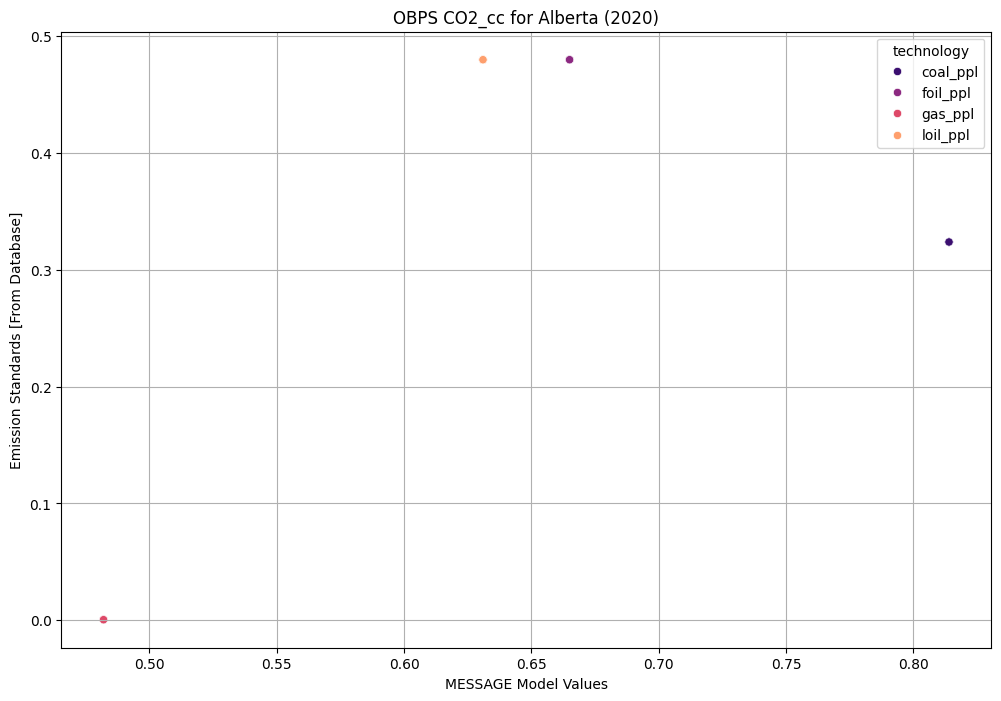

In [131]:
merged_data = pd.merge(CALCULATED_data, NEW_data, left_on=["year_act","technology"], right_on=["time", "technology"], how="inner", suffixes=("_calc", "_new"))
merged_data = merged_data[["technology", "OBPS", "conversion_to_KWa", "year_vtg"]]
merged_data.rename(columns={"year_vtg": "years"}, inplace=True)
merged_data = merged_data[merged_data["years"].isin(chosen_years)]
merged_data["marker"] = merged_data["technology"].map(marker_styles)

#plt.figure(figsize=(12, 8))

scatter_fig, axis1 = plt.subplots(figsize=(12, 8))
#axis2 = axis1.twinx()



#database_data = merged_data[["technology", "conversion_to_KWa"]].drop_duplicates()
#database_data["marker"] = marker_styles["Database"]
#database_data["source"] = "Database"

sns.scatterplot(
    x="OBPS",
    y="conversion_to_KWa",
    hue="technology",
    data=merged_data,
    palette="magma",
    #style="marker",
    #markers=False,
    legend=True,
    ax=axis1  
)


#model_data = merged_data[["technology", "OBPS"]].drop_duplicates()
#model_data["marker"] = marker_styles["MESSAGE Model"]
#model_data["source"] = "MESSAGE Model"

#combined_data = pd.concat([database_data, model_data])
#combined_data["marker"] = combined_data["source"].map({"Database": "x", "MESSAGE Model": "^"})

'''
sns.scatterplot(
    x="OBPS",
    y="conversion_to_KWa",
    hue="technology",
    data=merged_data,
    palette="magma",
    style="marker",
    markers=False,
    ax=axis2,
    legend=False 
)
'''

axis1.set_title(f"OBPS {chosen_relation} for {chosen_prov} ({', '.join(map(str, chosen_years))})")
axis1.set_xlabel("MESSAGE Model Values")
axis1.set_ylabel("Emission Standards [From Database]")
#axis1.legend(title="Technology")
axis1.grid(True)

#axis2.set_title(f"OBPS {chosen_relation} for {chosen_prov} ({', '.join(map(str, chosen_years))})")
##axis2.set_xlabel("Technology")
#axis2.set_ylabel("Emission Standards [From Database]")

#axis2.set_yticks(chosen_years)
#axis2.set_ylabel("Emission Standards [From Database]", color="black")
#axis2.tick_params(axis='y', labelcolor="black")


#plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
#plt.title(f"{chosen_relation} vs. Technologies for {chosen_prov} ({', '.join(map(str, chosen_years))})")
#plt.xlabel("Technology")
#plt.ylabel("Emission Standards")
#plt.grid(axis='y')

In [ ]:
def plot_tech_by_year_y_vs_tech(final_df, new_obps, chosen_tech, chosen_prov, chosen_relation, chosen_years):
    """
    Plots "OBPS" and "conversion_to_KWa" on the y-axis, with "technologies" on the x-axis,
    binned by year.

    Args:
        final_df (pd.DataFrame): DataFrame containing calculated data.
        new_obps (pd.DataFrame): DataFrame containing new OBPS data.
        chosen_tech (str or list): Technology or list of technologies to filter.
        chosen_prov (str): Province to filter.
        chosen_relation (str): Relation to filter.
        chosen_years (list): List of years to filter.
    """

    # Ensure chosen_tech is a list
    if not isinstance(chosen_tech, list):
        chosen_tech = [chosen_tech]

    # Filter and merge data
    merged_data_list = []
    for tech in chosen_tech:
        CALCULATED_data = final_df.loc[
            (final_df["technology"] == tech)
            & (final_df["node_loc"] == chosen_prov)
            & (final_df["relation"] == chosen_relation)
            & (final_df["year_act"].isin(chosen_years))
        ].copy()
        CALCULATED_data.fillna({"OBPS": 0}, inplace=True)

        NEW_data = new_obps.loc[
            (new_obps["technology"] == tech)
            & (new_obps["region"] == chosen_prov)
            & (new_obps["variable"].str.contains("Standard"))
            & (new_obps["time"].isin(chosen_years))
        ].copy()
        NEW_data.fillna({"conversion_to_KWa": 0}, inplace=True)

        #merged_data = pd.merge(
        #    CALCULATED_data, NEW_data, left_on="year_act", right_on="time", how="inner"
        #)
        merged_data = pd.merge(CALCULATED_data, NEW_data, left_on=["year_act","technology"], right_on=["time", "technology"], how="inner", suffixes=("_calc", "_new"))
        #merged_data.drop(columns=["technology_new"], inplace=True)
        merged_data = merged_data[["technology", "OBPS", "conversion_to_KWa", "year_vtg"]]
        merged_data.rename(columns={"year_vtg": "years"}, inplace=True)
        merged_data = merged_data[merged_data["years"].isin(chosen_years)]
        merged_data["marker"] = merged_data["technology"].map(marker_styles)
        
        merged_data_list.append(merged_data)

    merged_all = pd.concat(merged_data_list)

    # Melt the dataframe to have OBPS and conversion_to_KWa as a single column
    melted_data = pd.melt(
        merged_all,
        id_vars=["technology", "year_act"],
        value_vars=["OBPS", "conversion_to_KWa"],
        var_name="OBPS_variable",
        value_name="merged_obps_value",
    )

    # Create the grouped bar plot
    plt.figure(figsize=(14, 8))
    sns.barplot(
        x="technology",
        y="merged_obps_value",
        hue="OBPS_variable",
        data=melted_data,
        palette="plasma",
    )

    plt.title(f"{chosen_relation} vs. Technologies for {chosen_prov} ({', '.join(map(str, chosen_years))})")
    plt.xlabel("Technology")
    plt.ylabel("Value (OBPS/Conversion to KWa)")
    plt.legend(title="Variable")
    plt.grid(axis='y')
    plt.show()

In [80]:
plot_tech_by_year_y_vs_tech(final_df, new_obps, chosen_tech, chosen_prov, chosen_relation, chosen_years)

KeyError: "The following id_vars or value_vars are not present in the DataFrame: ['technology']"